# Clash Royale deck as a portfolio

Run the cells in order. Install once: `pip install requests pandas numpy matplotlib`.

## 1. Setup

In [3]:
import os
import time
from collections import defaultdict
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

# Set your API token as an environment variable (CR_API_KEY) or paste it below. Never commit a real token.
API_KEY = os.environ.get("CR_API_KEY", "paste_your_token_here")
HEADERS = {"Authorization": f"Bearer {API_KEY}"}
SEED_TAG = "#Q9QQ28P8Q"   # your own player tag
N_PLAYERS = 300           # players to crawl
MIN_GAMES = 20            # min games for a card to be eligible in the optimizer
MIN_PAIR = 10             # min co-occurrences for a pair synergy to count

## 2. Data collection (breadth-first crawl through opponents)

In [4]:
def get_battles(tag):
    url = f"https://api.clashroyale.com/v1/players/{tag.replace('#', '%23')}/battlelog"
    r = requests.get(url, headers=HEADERS)
    return r.json() if r.status_code == 200 else []


def parse_battles(raw):
    records, opp_tags = [], []
    for b in raw:
        try:
            team = b["team"][0]
            opp = b["opponent"][0]
            cards = frozenset(c["name"] for c in team["cards"])
            opp_tags.append(opp["tag"])
            if len(cards) == 8:
                records.append((cards, team["crowns"] > opp["crowns"]))
        except (KeyError, IndexError):
            continue
    return records, opp_tags


def crawl(seed, n_players):
    visited, queue, all_records = set(), [seed], []
    while len(visited) < n_players and queue:
        tag = queue.pop(0)
        if tag in visited:
            continue
        visited.add(tag)
        records, new_tags = parse_battles(get_battles(tag))
        all_records.extend(records)
        queue.extend(t for t in new_tags if t not in visited)
        if len(visited) % 20 == 0:
            print(f"{len(visited)} players - {len(all_records)} battles")
        time.sleep(0.1)
    return all_records


all_records = crawl(SEED_TAG, N_PLAYERS)
print(f"Total battles: {len(all_records)}")

# Optional: save/load so you don't have to re-crawl (takes ~6 min)
# import pickle
# pickle.dump(all_records, open("records.pkl", "wb"))
# all_records = pickle.load(open("records.pkl", "rb"))

20 players - 349 battles
40 players - 783 battles
60 players - 990 battles
80 players - 1608 battles
100 players - 2208 battles
120 players - 2640 battles
140 players - 3223 battles
160 players - 3771 battles
180 players - 4334 battles
200 players - 4832 battles
220 players - 5204 battles
240 players - 5827 battles
260 players - 6423 battles
280 players - 6703 battles
300 players - 7212 battles
Total battles: 7212


## 3. mu (card win rates) and S (synergy between cards)

In [5]:
def card_stats(records):
    wins, games = defaultdict(int), defaultdict(int)
    for deck, won in records:
        for c in deck:
            games[c] += 1
            wins[c] += int(won)
    mu = pd.Series({c: wins[c] / games[c] for c in games}).sort_values(ascending=False)
    n = pd.Series(games).reindex(mu.index)
    return mu, n


def synergy_matrix(records, mu, min_pair=MIN_PAIR):
    """S[i,j] = win rate of decks containing both i and j, minus the average of
    their individual win rates. Pairs with fewer than min_pair games are set to 0."""
    cards = mu.index.tolist()
    idx = {c: i for i, c in enumerate(cards)}
    k = len(cards)
    pw, pg = np.zeros((k, k)), np.zeros((k, k))
    for deck, won in records:
        for a, b in combinations(deck, 2):
            i, j = idx[a], idx[b]
            for x, y in ((i, j), (j, i)):      # fill BOTH triangles
                pw[x, y] += int(won)
                pg[x, y] += 1
    pair_wr = np.divide(pw, pg, out=np.zeros((k, k)), where=pg > 0)
    m = mu.values.astype(float)
    baseline = (m[:, None] + m[None, :]) / 2
    S = np.where(pg >= min_pair, pair_wr - baseline, 0.0)
    np.fill_diagonal(S, 0.0)
    return pd.DataFrame(S, index=cards, columns=cards), pd.DataFrame(pg, index=cards, columns=cards)


mu, n_games = card_stats(all_records)
S, pair_n = synergy_matrix(all_records, mu)
print(f"Cards: {len(mu)}")
print(mu.head(10))

pairs = [(a, b, S.loc[a, b], int(pair_n.loc[a, b])) for a, b in combinations(mu.index, 2) if S.loc[a, b] != 0]
pairs.sort(key=lambda x: x[2], reverse=True)
print("\nTop 5 synergistic pairs:")
for a, b, s, c in pairs[:5]:
    print(f"  {a} + {b}: {s:+.4f} (n={c})")

Cards: 123
Night Witch        0.596273
Monk               0.594937
Goblin Drill       0.581081
Fire Spirit        0.580189
Goblin Giant       0.571429
Skeleton Barrel    0.566745
Rascals            0.566265
Hog Rider          0.561674
Goblin Gang        0.560180
Mini P.E.K.K.A     0.559788
dtype: float64

Top 5 synergistic pairs:
  Clone + Elixir Golem: +0.5215 (n=11)
  Skeleton Army + Bomb Tower: +0.4082 (n=11)
  Witch + Bomb Tower: +0.4045 (n=11)
  Zappies + Hunter: +0.3842 (n=14)
  Spear Goblins + Furnace: +0.3836 (n=12)


## 4. Elixir costs

In [6]:
elixir_costs = {
    "Knight": 3, "Archers": 3, "Goblins": 2, "Giant": 5, "P.E.K.K.A": 7, "Minions": 3,
    "Balloon": 5, "Witch": 5, "Barbarians": 5, "Golem": 8, "Skeletons": 1, "Valkyrie": 4,
    "Skeleton Army": 3, "Healer": 4, "Dragon": 4, "Prince": 5, "Wizard": 5,
    "Mini P.E.K.K.A": 4, "Spear Goblins": 2, "Giant Skeleton": 6, "Hog Rider": 4,
    "Minion Horde": 5, "Ice Wizard": 3, "Tombstone": 3, "Cannon": 3, "Goblin Barrel": 3,
    "Fireball": 4, "Arrow": 3, "Zap": 2, "Bomb Tower": 4, "Barbarian Hut": 7, "Mortar": 4,
    "Inferno Tower": 5, "Goblin Hut": 5, "Tesla": 4, "Lightning": 6, "Freeze": 4,
    "Mirror": 3, "Rage": 3, "Rocket": 6, "X-Bow": 6, "Three Musketeers": 9, "Poison": 4,
    "Graveyard": 5, "Ice Spirit": 1, "Fire Spirit": 1, "Miner": 3, "Sparky": 6, "Bowler": 5,
    "Lava Hound": 7, "Ice Golem": 2, "Inferno Dragon": 4, "Mega Minion": 3,
    "Dark Prince": 4, "Electro Wizard": 4, "Royal Giant": 6, "Guards": 3, "Princess": 3,
    "Tornado": 3, "Mega Knight": 7, "Royal Recruits": 7, "Night Witch": 4, "Bats": 2,
    "Goblin Gang": 3, "Electro Dragon": 5, "Flying Machine": 4, "Wall Breakers": 2,
    "Royal Hogs": 5, "Goblin Giant": 6, "Healers": 4, "Cannon Cart": 5, "Skeleton Barrel": 3,
    "Rascals": 5, "Zappies": 4, "Electro Giant": 7, "Firecracker": 3, "Skeleton King": 4,
    "Archer Queen": 5, "Golden Knight": 4, "Skeleton Guard": 3, "Monk": 5,
    "Barbarian King": 7, "Elite Barbarians": 6, "Goblin Demolisher": 5, "Goblin Machine": 5,
    "Goblinstein": 5, "Goblin Curse": 2, "Rune Giant": 7, "Goblin Cage": 4,
    "Goblin Monster": 5, "Little Prince": 3, "Mighty Miner": 4, "Electro Spirit": 1,
    "Super Witch": 7, "Phoenix": 4, "Earthquake": 3, "Giant Snowball": 2, "Log": 2,
    "Lumberjack": 4, "Battle Ram": 4, "Bandit": 3, "Royal Ghost": 3, "Ram Rider": 5,
    "Clone": 3, "Heal Spirit": 1, "Magic Archer": 4, "Elixir Golem": 3, "Battle Healer": 4,
    "Fisherman": 3, "Bomber": 2, "Suspicious Bush": 3, "Elixir Collector": 6,
    "Mother Witch": 4,
}


def get_elixir(card):
    return elixir_costs.get(card, 4)

## 5. Greedy optimizer + efficient frontier

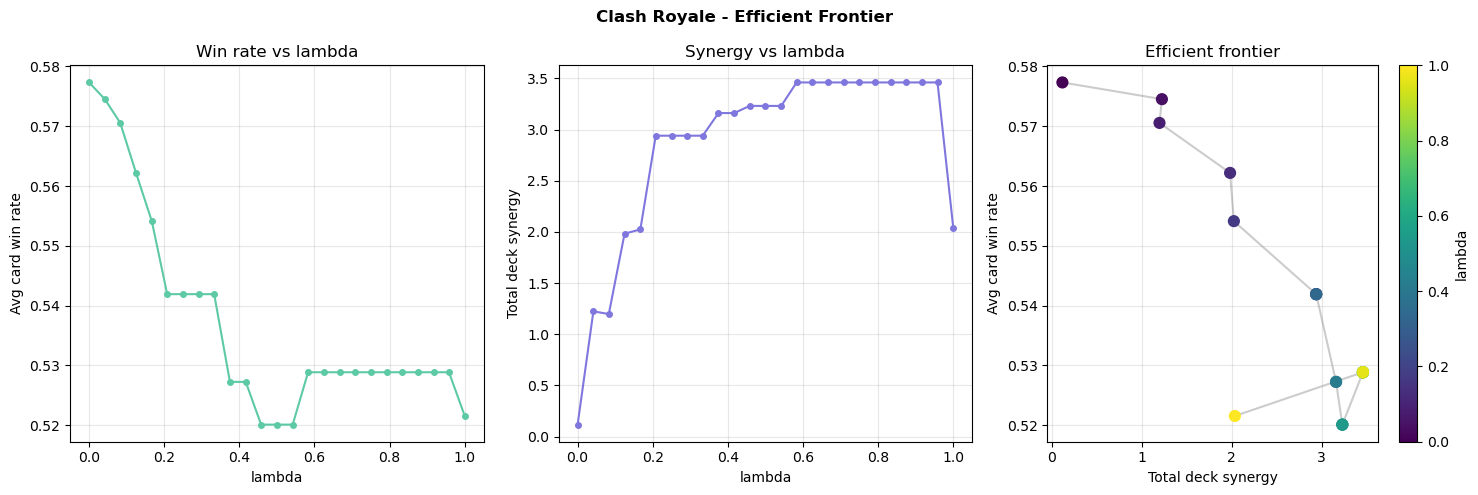

In [7]:
def greedy_deck(mu, S, lam=0.5, deck_size=8, elixir_cap=32, min_games=MIN_GAMES):
    eligible = [c for c in mu.index if n_games[c] >= min_games]
    selected, remaining = [], set(eligible)
    while len(selected) < deck_size and remaining:
        used = sum(get_elixir(c) for c in selected)
        best, best_score = None, -np.inf
        for c in remaining:
            if used + get_elixir(c) > elixir_cap:
                continue
            score = (1 - lam) * mu[c] + lam * sum(S.loc[c, s] for s in selected)
            if score > best_score:
                best, best_score = c, score
        if best is None:
            break
        selected.append(best)
        remaining.discard(best)
    return selected


def deck_score(deck, mu, S):
    wr = np.mean([mu[c] for c in deck])
    syn = sum(S.loc[a, b] for a, b in combinations(deck, 2))
    elx = np.mean([get_elixir(c) for c in deck])
    return wr, syn, elx


lambdas = np.round(np.linspace(0, 1, 25), 3)
frontier = {}
for lam in lambdas:
    d = greedy_deck(mu, S, lam=lam)
    wr, syn, elx = deck_score(d, mu, S)
    frontier[lam] = {"deck": d, "win_rate": wr, "synergy": syn, "avg_elixir": elx}

lam_vals = list(frontier)
wr_vals = [frontier[l]["win_rate"] for l in lam_vals]
syn_vals = [frontier[l]["synergy"] for l in lam_vals]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Clash Royale - Efficient Frontier", fontweight="bold")
axes[0].plot(lam_vals, wr_vals, "o-", color="#5DCAA5", markersize=4)
axes[0].set(xlabel="lambda", ylabel="Avg card win rate", title="Win rate vs lambda")
axes[1].plot(lam_vals, syn_vals, "o-", color="#7F77DD", markersize=4)
axes[1].set(xlabel="lambda", ylabel="Total deck synergy", title="Synergy vs lambda")
sc = axes[2].scatter(syn_vals, wr_vals, c=lam_vals, cmap="viridis", s=60, zorder=3)
axes[2].plot(syn_vals, wr_vals, color="gray", alpha=0.4)
axes[2].set(xlabel="Total deck synergy", ylabel="Avg card win rate", title="Efficient frontier")
plt.colorbar(sc, ax=axes[2], label="lambda")
for a in axes:
    a.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Pick the optimal deck (highest win rate among decks with positive synergy)

In [8]:
cands = {l: d for l, d in frontier.items() if d["synergy"] > 0}
best_lam = max(cands, key=lambda l: cands[l]["win_rate"]) if cands else lam_vals[0]
best = frontier[best_lam]
print(f"Optimal lambda: {best_lam}")
for c in best["deck"]:
    print(f"  {c:25s} win_rate={mu[c]:.3f} elixir={get_elixir(c)}")
print(f"Win rate {best['win_rate']:.3f} | synergy {best['synergy']:.3f} | avg elixir {best['avg_elixir']:.2f}")

Optimal lambda: 0.0
  Night Witch               win_rate=0.596 elixir=4
  Monk                      win_rate=0.595 elixir=5
  Goblin Drill              win_rate=0.581 elixir=4
  Fire Spirit               win_rate=0.580 elixir=1
  Goblin Giant              win_rate=0.571 elixir=6
  Skeleton Barrel           win_rate=0.567 elixir=3
  Rascals                   win_rate=0.566 elixir=5
  Hog Rider                 win_rate=0.562 elixir=4
Win rate 0.577 | synergy 0.117 | avg elixir 4.00


## 7. Friends' decks vs the frontier

[Baro] win_rate=0.498 synergy=-0.093 avg_elixir=4.12
[Pitz] win_rate=0.505 synergy=0.789 avg_elixir=3.38
[Andre] not in dataset: ['Log']
[Andre] win_rate=0.530 synergy=-0.638 avg_elixir=3.86
[Riki] win_rate=0.520 synergy=0.336 avg_elixir=3.00
[Riki 2] not in dataset: ['Log']
[Riki 2] win_rate=0.514 synergy=-0.604 avg_elixir=2.71


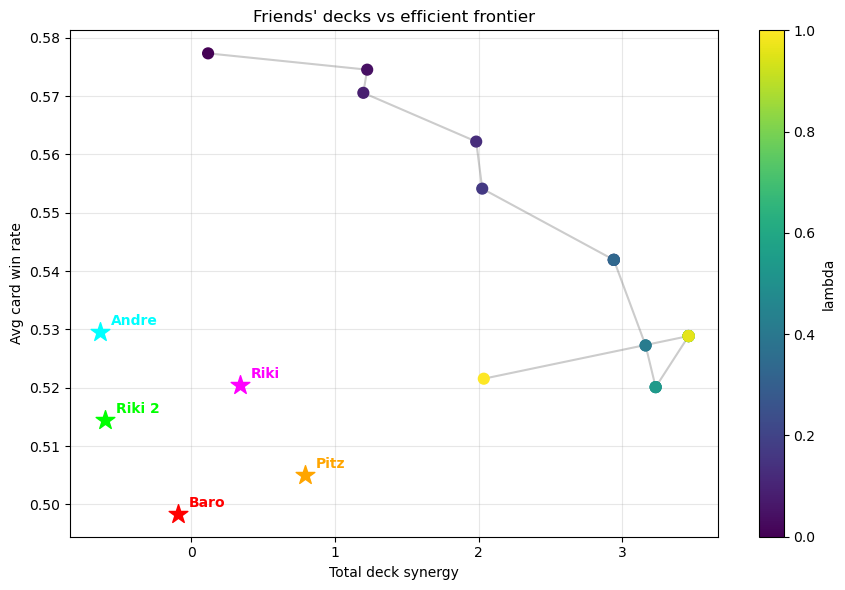

In [9]:
decks = {
    "Baro": ["Barbarians", "Goblinstein", "Archers", "Skeletons",
             "Fireball", "Elite Barbarians", "Elixir Collector", "Cannon"],
    "Pitz": ["Suspicious Bush", "Zap", "Bomber", "Goblin Barrel",
             "Elite Barbarians", "Fireball", "Electro Wizard", "Guards"],
    "Andre": ["Archers", "Log", "Valkyrie", "Prince",
              "Guards", "Hog Rider", "Cannon", "Electro Dragon"],
    "Riki": ["Mega Knight", "Cannon", "Skeleton Barrel", "Suspicious Bush",
             "Wall Breakers", "Goblin Barrel", "Goblins", "Skeletons"],
    "Riki 2": ["Cannon", "Fireball", "Hog Rider", "Magic Archer",
               "Ice Spirit", "Skeletons", "Ice Golem", "Log"],
}
colors = ["red", "orange", "cyan", "magenta", "lime"]

fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(syn_vals, wr_vals, c=lam_vals, cmap="viridis", s=60, zorder=3)
ax.plot(syn_vals, wr_vals, color="gray", alpha=0.4)
for (name, deck), col in zip(decks.items(), colors):
    present = [c for c in deck if c in mu.index]
    missing = [c for c in deck if c not in mu.index]
    if missing:
        print(f"[{name}] not in dataset: {missing}")
    wr, syn, elx = deck_score(present, mu, S)
    print(f"[{name}] win_rate={wr:.3f} synergy={syn:.3f} avg_elixir={elx:.2f}")
    ax.scatter(syn, wr, color=col, s=200, marker="*", zorder=5)
    ax.annotate(name, (syn, wr), textcoords="offset points", xytext=(8, 5),
                color=col, fontweight="bold")
plt.colorbar(sc, ax=ax, label="lambda")
ax.set(xlabel="Total deck synergy", ylabel="Avg card win rate",
       title="Friends' decks vs efficient frontier")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()